# Temporal Trends

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/dataset.csv', parse_dates=['order_date', 'shipping_date'])

df = df.drop_duplicates('order_id', ignore_index=True)

In [2]:
sns.set_theme()

from scripts import visualization_config

## How does order volume change over time?

In [3]:
orders_by_month = pd.DataFrame(df.groupby(df['order_date'].dt.to_period('M')).size())
orders_by_month['month'] = orders_by_month[0]
orders_by_month = orders_by_month.drop(columns=[0])

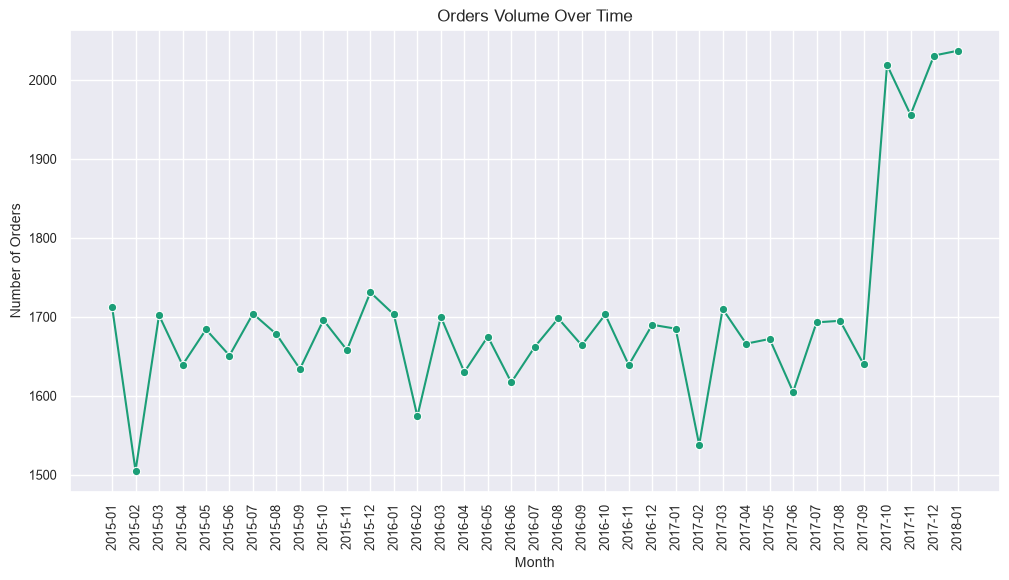

In [4]:
orders_by_month.index = orders_by_month.index.astype(str)

plt.figure(figsize=(12, 6))

sns.lineplot(data=orders_by_month, markers=True, legend=False, palette='Dark2')

plt.title('Orders Volume Over Time')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=90)

plt.savefig('../visualizations/orders-volume-over-time.png', bbox_inches='tight')
plt.show()

The chart clearly shows that order volumes were somewhere consistent up until September 2017. Then, there's a sudden spike in the last four months.

In [5]:
before_spike = orders_by_month.loc['2015-01':'2017-09']
after_spike = orders_by_month.loc['2017-10':'2018-01']

print(before_spike.describe())
print(after_spike.describe())

print(f'Average order volume difference in first 33 months and last 4 months: {int(after_spike.mean().iloc[0] - before_spike.mean().iloc[0])} orders')

             month
count    33.000000
mean   1662.242424
std      50.376104
min    1505.000000
25%    1639.000000
50%    1675.000000
75%    1698.000000
max    1731.000000
             month
count     4.000000
mean   2010.750000
std      37.259227
min    1956.000000
25%    2003.250000
50%    2025.000000
75%    2032.500000
max    2037.000000
Average order volume difference in first 33 months and last 4 months: 348 orders


From the two tables we can see that the average order volumes jumped by 348 in the last four months. The minimum number of orders also jumped from 1505 to 1956, and the maximum from 1731 to 2037.

With this data we can safely confirm that the last 4 months were the most successful, in terms of order volumes.

**NOTE**: This only counts order volumes. It doesn't count items per order, or profit.

## Are there seasonal or day-of-week patterns in delivery delays?

## Has shipping performance improved or deteriorated throughout the dataset period?

## Are there particular periods associated with increased operational inefficiencies?